# LandShift D3.5 — Section 4.1
# Ecosystem Services provided by Ecosystem Types

| | |
|---|---|
| **Project** | LandShift — Horizon Europe, Grant Agreement No. 101182007 |
| **Task** | T3.3 — Mapping ecosystem services linked with past, current, and projected LULUCF |
| **Lead** | University of Geneva (UNIGE) |
| **Collaborators** | POLIMI, UNIBAS, ECoE, BFRS |
| **Reference** | D3.5 Ecosystem services & landscape ecology, §4.1 |
| **FAIR compliance** | Outputs are open CSV / PNG / GeoTIFF / MD; notebook is fully reproducible |

---

## Purpose

This notebook implements the **Tier 3 LandShift product** described in §4.1 of D3.5.  
It integrates Tier-2 outputs that are assumed to have already been computed
(see the [WP3 folder of the HE-LandShift repository](https://github.com/LivingEarthLab/HE-LandShift/tree/main/WP3)):

1. **MAES ecosystem extent raster** — integer raster classifying every pixel into a MAES Level-2 ecosystem type (`<name>_maesL2.tif`).
2. **InVEST ecosystem service rasters** — outputs of `ecosystem_services/ecosystem_services.ipynb` (carbon storage, sediment, nutrient export, habitat quality, pollination).
3. *(optional)* **SEEA-EA ecosystem condition raster** — 1–5 score from `ecosystem_condition/ecosystem_condition.ipynb` (ESAI is no longer used).

The notebook then:
- Builds the **SEEA-EA Ecosystem Extent Account** (Table 2 of D3.5)
- Performs a pixel-level **spatial overlay** to attribute service values to ecosystem types
- Compiles the **SEEA-EA Physical Supply Table** (Table 3 of D3.5), aggregating each service according to its **unit basis** (per hectare, per pixel, depth in mm, or dimensionless index)
- Optionally stratifies supply by **ecosystem condition** (Good / Moderate / Degraded, §4.1.1.5)
- Optionally computes **monetary valuation** (§4.1.1.6) — only for annual flows
- Exports the **service maps and a multiband GeoTIFFs of mean service density and of per-pixel supply by ecosystem type** on the MAES grid
- Runs a full set of **quality checks** (§4.1.2)
- Exports all tables, figures, and a Markdown processing report

### Six-step workflow (D3.5 §4.1.1)

| Step | Description | D3.5 Reference |
|------|-------------|----------------|
| 1 | Establish the Ecosystem Extent Baseline (MAES) | §4.1.1.1 |
| 2 | Verify and align the InVEST service rasters | §4.1.1.2 |
| 3 | Spatial overlay and attribution | §4.1.1.3 |
| 4 | Aggregate — compile the Physical Supply Table | §4.1.1.4 |
| 5 | *(Optional)* Link to ecosystem condition (SEEA-EA score) | §4.1.1.5 |
| 6 | *(Optional)* Monetary valuation | §4.1.1.6 |

---

## How to use this notebook

1. Run **Section 0** to install and import dependencies.
2. Edit **Section 1** (Configuration) — set `MAES_RASTER` and the `SERVICES` dictionary (**declare the unit basis of every raster**).
3. Run all cells top-to-bottom. Outputs land in `OUTPUT_DIR`.
4. To test without real data, keep `DEMO_MODE = True` (Section A generates synthetic rasters).

> ⚠️ **Why the unit basis matters.** D3.5 Eq. 4.1.1.3 (Total = Σ S·A) is only valid when the raster holds a
> *per-hectare density*.  InVEST layers can be per hectare, per pixel, or dimensionless indices (habitat quality,
> pollinator supply).  Multiplying an index by an area, or a per-pixel value by an area, produces meaningless totals,
> so each service declares how it must be aggregated.
>
> ℹ️ **No economic valuation is produced by default** (D3.5 §3). Monetary valuation is an
> optional extension, restricted to annual flows, and follows SNA exchange-value principles.

---
## Section 0 — Dependencies

In [20]:
# Install required packages if not already present.
# Comment out this cell if working in a pre-configured environment.
import subprocess, sys

PACKAGES = ["numpy", "pandas", "rasterio", "matplotlib", "affine", "scipy"]
for pkg in PACKAGES:
    subprocess.run([sys.executable, "-m", "pip", "install", pkg, "-q"], check=False)

print("All packages ready.")

All packages ready.


In [21]:
import datetime
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.ticker import ScalarFormatter

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

print(f"numpy    {np.__version__}")
print(f"pandas   {pd.__version__}")
print(f"rasterio {rasterio.__version__}")
print("Imports OK.")

numpy    2.3.4
pandas   3.0.2
rasterio 1.5.0
Imports OK.


---
## Section 1 — Configuration

**Edit the variables in this cell before running the rest of the notebook.**

In [ ]:
# ── Input — MAES ecosystem extent raster (Tier-2 output) ─────────────────────
#   dtype  : integer (uint8 / int16)
#   values : MAES Level-2 class codes (101 Urban … 107 Wetlands, 200 Rivers and lakes)
#   CRS    : any projected CRS with metre units (e.g. EPSG:3035)
MAES_RASTER = Path("PATH_TO_MAES_RASTER")

# Lookup table  →  required columns: 'maes_code' (int), 'ecosystem_type' (str)
#                  optional column : 'maes_color' (hex string, e.g. '#2ca25f')
MAES_LOOKUP_CSV = Path("PATH_TO/maes_lookup.csv")

# ── Input — InVEST service rasters (Tier-2 outputs of ecosystem_services.ipynb) ──
# One entry per service.  Fields:
#   path        : raster path, or a LIST of paths (e.g. one per pollinator guild) that are
#                 combined pixel-wise by `combine`
#   label       : human-readable name used in tables and figures
#   basis       : how the raster values must be aggregated (D3.5 Eq. 4.1.1.3)
#                   'per_ha'    value is a density per hectare      → total = Σ S·A_ha
#                   'per_pixel' value is an amount per pixel        → total = Σ S
#                   'depth_mm'  value is a depth in mm (e.g. water yield) → total m³ = Σ S·10·A_ha
#                   'index'     dimensionless index (0–1 …)         → mean only, no total
#   unit        : unit of the raster values
#   unit_total  : unit of the total (None for indices)
#   kind        : 'stock' | 'flow' | 'pressure' | 'index'
#                   (only 'flow' services can be valued monetarily; 'pressure' = e.g. nutrient export)
#   group       : services of the same group overlap (e.g. carbon storage vs sequestration) and
#                 must not be added up — double-counting guard (§4.1.2)
#   year        : modelling year (checked against ACCOUNTING_YEAR, §4.1.2)
#   valid_range : (min, max) plausible range, None = open end (quality check)
#   combine     : 'mean' | 'sum' when `path` is a list (default: mean for index, sum otherwise)
#   price_factor: optional factor converting the total to the unit of its price (Step 6)
#
# ⚠️ Units depend on the InVEST version and model settings.  Check the model documentation and
#    the `raster_values_summary.csv` written by the models, and set `basis` accordingly.
SERVICES = {
    "carbon_storage": dict(
        path=Path("inputs/invest/carbon/c_storage_bas.tif"),
        label="Carbon storage", basis="per_ha", unit="Mg C ha⁻¹", unit_total="Mg C",
        kind="stock", group="carbon", year=2024, valid_range=(0, None)),
    "sediment_avoided_export": dict(
        path=Path("inputs/invest/sediment/avoided_export.tif"),
        label="Sediment retention (avoided export)", basis="per_ha", unit="t ha⁻¹ yr⁻¹",
        unit_total="t yr⁻¹", kind="flow", group="sediment", year=2024, valid_range=(0, None)),
    "n_total_export": dict(
        path=Path("inputs/invest/ndr/n_total_export.tif"),
        label="Nitrogen export", basis="per_ha", unit="kg ha⁻¹ yr⁻¹", unit_total="kg yr⁻¹",
        kind="pressure", group="nutrient", year=2024, valid_range=(0, None)),
    "habitat_quality": dict(
        path=Path("inputs/invest/habitat/quality_c.tif"),
        label="Habitat quality", basis="index", unit="index (0–1)", unit_total=None,
        kind="index", group="habitat", year=2024, valid_range=(0, 1)),
    "pollinator_supply": dict(
        path=sorted(Path("inputs/invest/pollination").glob("pollinator_supply_*.tif")),
        label="Pollinator supply (mean of guilds)", basis="index", unit="index (0–1)", unit_total=None,
        kind="index", group="pollination", year=2024, valid_range=(0, 1), combine="mean"),
    # Example of a flow-type carbon service (needs `calc_sequestration = True` in the InVEST carbon run):
    # "carbon_sequestration": dict(
    #     path=Path("inputs/invest/carbon/c_change_bas_fut.tif"),
    #     label="Carbon sequestration", basis="per_ha", unit="Mg C ha⁻¹ yr⁻¹", unit_total="Mg C yr⁻¹",
    #     kind="flow", group="carbon", year=2024, valid_range=(None, None),
    #     price_factor=44/12),          # Mg C → t CO₂e, so that the price can be given per t CO₂e
}

# ── Input — SEEA-EA ecosystem condition raster (optional; set to None to skip Step 5) ──
#   Output of WP3 `ecosystem_condition.ipynb` (`ecosystem_condition_map.tif`):
#   5 = Very Good … 1 = Very Poor, NoData for non-natural ecosystems.
CONDITION_RASTER = Path("PATH_TO_ECOSYSTEM_CONDITION_RASTER")   # or None
CONDITION_YEAR   = 2025

# Mapping of the 5-point SEEA-EA score to the three classes used in D3.5 §4.1.1.5
SEEA_TO_CLASS = {5: "Good", 4: "Good", 3: "Moderate", 2: "Degraded", 1: "Degraded"}
CLASS_ORDER   = ["Good", "Moderate", "Degraded", "Not assessed"]
CLASS_CODE    = {"Good": 3, "Moderate": 2, "Degraded": 1, "Not assessed": 0}
CLASS_COLOURS = {"Good": "#2ca25f", "Moderate": "#fee08b", "Degraded": "#d73027",
                 "Not assessed": "#d9d9d9"}
MIN_PIXELS_FOR_RATIO = 30      # minimum pixels per class to report a Degraded/Good ratio
FOCUS_SERVICE        = None    # service shown in the Step-5 figures (None = first additive service)

# ── Output ────────────────────────────────────────────────────────────────────
OUTPUT_DIR      = Path("outputs/section_4_1")
ACCOUNTING_YEAR = 2025
LIVING_SPACE    = "Basilicata"   # e.g. 'Basilicata', 'Bourgogne', …

# ── Spatial settings ─────────────────────────────────────────────────────────
# True  → reproject/resample service rasters to match the MAES grid (recommended).
# False → assume all rasters are already perfectly co-registered.
ALIGN_SERVICES         = True
RESAMPLE_METHOD        = Resampling.bilinear   # continuous service layers; the condition raster always uses nearest
PIXEL_AREA_HA_OVERRIDE = None      # set e.g. 0.01 to force a 10 m × 10 m pixel (0.01 ha)
MAES_EXCLUDE_CODES     = [0, 255]  # pixel values treated as no-data / non-ecosystem
SERVICE_NODATA         = None      # None = read from raster metadata

# ── Quality-check thresholds ─────────────────────────────────────────────────
MIN_VALID_PCT = 90.0   # ecosystem types with a smaller share of valid service pixels are flagged

# ── Monetary valuation (Step 6, optional) ────────────────────────────────────
# Keys must match SERVICES keys; value = price per unit of the service total
# (after `price_factor`, if any).  Only services with kind='flow' are valued.
# Empty = no valuation (default, D3.5 §3).
PRICE_PER_UNIT = {}
CURRENCY = "EUR"

# ── Demo mode ─────────────────────────────────────────────────────────────────
# True  → synthetic rasters are generated; real input paths are ignored.
# False → production run; all paths above must point to real files.
DEMO_MODE = False

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration loaded.")
print(f"  Living Space    : {LIVING_SPACE}")
print(f"  Accounting year : {ACCOUNTING_YEAR}")
print(f"  Services        : {list(SERVICES)}")
print(f"  Output folder   : {OUTPUT_DIR.resolve()}")
print(f"  Demo mode       : {DEMO_MODE}")

Configuration loaded.
  Living Space    : Basilicata
  Accounting year : 2025
  Services        : ['carbon_storage', 'sediment_avoided_export', 'n_total_export', 'habitat_quality', 'pollinator_supply']
  Output folder   : /Users/gregorygiuliani/Desktop/codeES_T3/outputs/section_4_1
  Demo mode       : False


---
## Section A — Synthetic Demo Data *(skip in production)*

When `DEMO_MODE = True` this section generates small synthetic GeoTIFFs that mimic
real MAES, InVEST and SEEA-EA condition outputs (real MAES codes 101–107), so the full notebook can be
executed and tested without any input files.  Service values depend on the condition score, so Step 5 shows a
visible effect.  All configuration paths are overwritten automatically.
Set `DEMO_MODE = False` in Section 1 to run on real data.

In [23]:
if DEMO_MODE:
    from rasterio.transform import from_origin
    from scipy.ndimage import gaussian_filter

    DEMO_DIR = OUTPUT_DIR / "_demo_inputs"
    DEMO_DIR.mkdir(parents=True, exist_ok=True)

    ROWS, COLS = 200, 200
    DEMO_RES   = 10.0
    DEMO_TF    = from_origin(2600000, 1200000, DEMO_RES, DEMO_RES)
    DEMO_CRS   = "EPSG:3035"
    rng        = np.random.default_rng(42)

    def write_tif(path, arr, dtype, nodata):
        with rasterio.open(path, "w", driver="GTiff", height=ROWS, width=COLS, count=1,
                           dtype=dtype, crs=DEMO_CRS, transform=DEMO_TF, nodata=nodata) as dst:
            dst.write(arr.astype(dtype), 1)
        return path

    # ── MAES raster with the real LandShift codes (bands + salt-and-pepper) ──
    maes_labels = {101: "Urban (Settlements and other artificial areas)", 102: "Cropland",
                   103: "Grassland", 104: "Forest and woodlands", 107: "Wetlands"}
    maes_colors = {101: "#d9a38f", 102: "#ffd21f", 103: "#d3e6b0", 104: "#7cb518", 107: "#b2e3e3"}
    codes = np.array(list(maes_labels), dtype=np.uint8)
    band_h = ROWS // len(codes)
    maes_demo = np.zeros((ROWS, COLS), dtype=np.uint8)
    for i, code in enumerate(codes):
        maes_demo[i * band_h:(i + 1) * band_h, :] = code
    noise = rng.random((ROWS, COLS)) < 0.08
    maes_demo[noise] = rng.choice(codes, size=noise.sum())
    demo_maes_path = write_tif(DEMO_DIR / "maes_level2_demo.tif", maes_demo, np.uint8, 0)

    demo_lookup_path = DEMO_DIR / "maes_lookup_demo.csv"
    pd.DataFrame({"maes_code": list(maes_labels), "ecosystem_type": list(maes_labels.values()),
                  "maes_color": [maes_colors[c] for c in maes_labels]}).to_csv(demo_lookup_path, index=False)

    # ── SEEA-EA condition (1–5) — natural ecosystems only, smooth spatial pattern ──
    field = gaussian_filter(rng.normal(size=(ROWS, COLS)), sigma=6)
    field = field / field.std()
    cond_mu = {103: 3.0, 104: 3.8, 107: 3.4}                       # cropland / urban: not scored
    cond_demo = np.full((ROWS, COLS), np.nan, dtype=np.float32)
    for code, mu in cond_mu.items():
        m = maes_demo == code
        cond_demo[m] = np.rint(mu + 0.9 * field[m]).clip(1, 5)
    cond_demo[(rng.random((ROWS, COLS)) < 0.02)] = np.nan          # a few gaps
    demo_cond_path = write_tif(DEMO_DIR / "ecosystem_condition_map_2024_demo.tif",
                               np.where(np.isnan(cond_demo), -9999.0, cond_demo), np.float32, -9999.0)

    # ── InVEST-like service rasters (per-type mean × condition effect) ──
    svc_means = {
        "carbon_storage"         : {101: 5,    102: 60,  103: 80,  104: 180, 107: 120},
        "sediment_avoided_export": {101: 0.2,  102: 1.2, 103: 2.5, 104: 4.0, 107: 0.8},
        "n_total_export"         : {101: 8.0,  102: 25,  103: 6.0, 104: 2.0, 107: 3.0},
        "habitat_quality"        : {101: 0.05, 102: 0.30, 103: 0.60, 104: 0.85, 107: 0.75},
        "pollinator_guild_A"     : {101: 0.05, 102: 0.40, 103: 0.60, 104: 0.55, 107: 0.30},
        "pollinator_guild_B"     : {101: 0.04, 102: 0.30, 103: 0.50, 104: 0.65, 107: 0.35},
    }
    cond_effect = np.nan_to_num((cond_demo - 3.0) / 2.0, nan=0.0)   # −1 … +1
    sign = {"n_total_export": -1.0}                                 # export is higher where condition is worse
    demo_paths = {}
    for name, means in svc_means.items():
        arr = np.zeros((ROWS, COLS), dtype=np.float32)
        for code, mu in means.items():
            m = maes_demo == code
            arr[m] = rng.normal(mu, mu * 0.12, m.sum())
        arr = arr * (1 + 0.25 * sign.get(name, 1.0) * cond_effect)
        arr = arr.clip(0, 1) if name in ("habitat_quality", "pollinator_guild_A", "pollinator_guild_B") else arr.clip(0)
        if name == "sediment_avoided_export":                       # a few missing pixels
            arr[rng.random((ROWS, COLS)) < 0.02] = -9999.0
        sub = DEMO_DIR / "invest"; sub.mkdir(exist_ok=True)
        demo_paths[name] = write_tif(sub / f"{name}.tif", arr, np.float32, -9999.0)

    # ── Override configuration ──
    MAES_RASTER, MAES_LOOKUP_CSV = demo_maes_path, demo_lookup_path
    CONDITION_RASTER, CONDITION_YEAR = demo_cond_path, ACCOUNTING_YEAR
    for key in ("carbon_storage", "sediment_avoided_export", "n_total_export", "habitat_quality"):
        SERVICES[key]["path"] = demo_paths[key]
    SERVICES["pollinator_supply"]["path"] = [demo_paths["pollinator_guild_A"], demo_paths["pollinator_guild_B"]]
    for spec in SERVICES.values():
        spec["year"] = ACCOUNTING_YEAR
    ALIGN_SERVICES = False
    PRICE_PER_UNIT = {"sediment_avoided_export": 3.0,   # demo only: indicative avoided-dredging cost, EUR per t
                      "carbon_storage": 50.0}           # demo only: will be REFUSED (stock, not an annual flow)

    print("Demo rasters created:")
    print(f"  MAES      : {MAES_RASTER.name}")
    print(f"  Condition : {CONDITION_RASTER.name}")
    for k, v in demo_paths.items():
        print(f"  {k}: {v.name}")
else:
    print("DEMO_MODE = False — using paths defined in Section 1.")

DEMO_MODE = False — using paths defined in Section 1.


---
## Section 2 — Helper Functions

In [24]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.1  Pixel area
# ─────────────────────────────────────────────────────────────────────────────
def get_pixel_area_ha(raster_path: Path) -> float:
    """
    Return pixel area in hectares from the raster affine transform.
    Assumes a projected CRS whose linear unit is the metre.
    Overridden by PIXEL_AREA_HA_OVERRIDE when set.
    """
    if PIXEL_AREA_HA_OVERRIDE is not None:
        return float(PIXEL_AREA_HA_OVERRIDE)
    with rasterio.open(raster_path) as src:
        res_x, res_y = abs(src.transform.a), abs(src.transform.e)
    return (res_x * res_y) / 10_000.0


# ─────────────────────────────────────────────────────────────────────────────
# 2.2  Spatial alignment  (implements §4.1.2 requirement)
# ─────────────────────────────────────────────────────────────────────────────
def align_to_maes(src_path, ref_path, dst_path,
                  resampling=Resampling.bilinear, src_nodata=None, dst_nodata=-9999.0):
    """
    Reproject and resample src_path to exactly match the CRS, resolution and extent
    of ref_path (the MAES raster).  Writes the result (float32) to dst_path.

    Implements §4.1.2: 'Maintain consistent spatial resolution between MAES and
    InVEST outputs.'  Use Resampling.nearest for categorical layers (condition classes).
    """
    with rasterio.open(ref_path) as ref:
        ref_crs, ref_tf, ref_h, ref_w = ref.crs, ref.transform, ref.height, ref.width

    with rasterio.open(src_path) as src:
        raw    = src.read(1).astype(np.float32)
        src_nd = src.nodata if src_nodata is None else src_nodata
        bad    = np.isnan(raw)
        if src_nd is not None:
            bad |= np.isclose(raw, src_nd)
        raw = np.where(bad, dst_nodata, raw)
        dst_data = np.full((ref_h, ref_w), dst_nodata, dtype=np.float32)
        reproject(source=raw, destination=dst_data,
                  src_transform=src.transform, src_crs=src.crs,
                  dst_transform=ref_tf,       dst_crs=ref_crs,
                  resampling=resampling, src_nodata=dst_nodata, dst_nodata=dst_nodata)

    with rasterio.open(dst_path, "w", driver="GTiff", height=ref_h, width=ref_w, count=1,
                       dtype=np.float32, crs=ref_crs, transform=ref_tf, nodata=dst_nodata) as dst:
        dst.write(dst_data, 1)
    return Path(dst_path)


def load_aligned_layer(path, basis, tag, resampling=None):
    """
    Read one raster on the MAES grid (float32, NaN = missing).

    The raster is re-gridded when its CRS / shape / transform differ from the MAES raster
    (if ALIGN_SERVICES is True; otherwise an error is raised).  For basis='per_pixel' the
    re-gridded values are rescaled by the pixel-area ratio so that totals are preserved.
    Returns (array, layer_info).
    """
    resampling = RESAMPLE_METHOD if resampling is None else resampling
    path = Path(path)
    with rasterio.open(path) as src:
        res_x, res_y = abs(src.transform.a), abs(src.transform.e)
        crs, shape, tf = str(src.crs), (src.height, src.width), src.transform
        nd_src = src.nodata if SERVICE_NODATA is None else SERVICE_NODATA

    same_grid = (crs == str(maes_crs) and shape == maes_arr.shape
                 and np.allclose(tuple(tf)[:6], tuple(maes_tf)[:6], atol=1e-6))
    info = {"file": path.name, "res_m": res_x, "crs": crs, "shape": shape,
            "same_grid": same_grid, "aligned": False}

    load_path, nd_load = path, nd_src
    if not same_grid:
        if not ALIGN_SERVICES:
            raise ValueError(f"{path.name}: grid differs from the MAES raster "
                             f"({res_x:.1f} m, {shape}, {crs}) and ALIGN_SERVICES is False.")
        load_path = align_to_maes(path, MAES_RASTER, ALIGNED_DIR / f"{tag}_aligned.tif",
                                  resampling, src_nodata=nd_src)
        nd_load, info["aligned"] = -9999.0, True

    with rasterio.open(load_path) as src:
        arr = src.read(1).astype(np.float32)
    bad = np.isnan(arr)
    if nd_load is not None:
        bad |= np.isclose(arr, nd_load)
    arr = np.where(bad, np.nan, arr).astype(np.float32)

    if basis == "per_pixel" and info["aligned"]:
        arr = arr * np.float32(pix_ha / (res_x * res_y / 10_000.0))   # assumes metre units
    return arr, info


# ─────────────────────────────────────────────────────────────────────────────
# 2.3  Aggregation by unit basis  (implements §4.1.1.3 – §4.1.1.4)
# ─────────────────────────────────────────────────────────────────────────────
def aggregate_values(vals: np.ndarray, basis: str, pixel_ha: float) -> dict:
    """
    Aggregate the pixel values of one zone according to the unit basis of the service:

        per_ha     Total = Σ S_p · A_p          (A in ha)        mean = mean(S)
        per_pixel  Total = Σ S_p                                  mean = Σ S_p / Σ A_p  (per ha)
        depth_mm   Total = Σ S_p · 10 · A_p     (m³; 1 mm over 1 ha = 10 m³)   mean = mean(S)
        index      no total (an index multiplied by an area has no physical meaning); mean = mean(S)

    Pixels with missing values are ignored.  Returns n_valid, area_valid_ha, mean, std, total
    (NaN when there are no valid pixels or the basis has no total).
    """
    valid = vals[~np.isnan(vals)]
    n = int(valid.size)
    out = {"n_valid": n, "area_valid_ha": n * pixel_ha, "mean": np.nan, "std": np.nan, "total": np.nan}
    if n == 0:
        return out
    if basis == "per_ha":
        out.update(mean=valid.mean(), std=valid.std(), total=valid.sum() * pixel_ha)
    elif basis == "per_pixel":
        out.update(mean=valid.mean() / pixel_ha, std=valid.std() / pixel_ha, total=valid.sum())
    elif basis == "depth_mm":
        out.update(mean=valid.mean(), std=valid.std(), total=valid.sum() * 10.0 * pixel_ha)
    elif basis == "index":
        out.update(mean=valid.mean(), std=valid.std())
    else:
        raise ValueError(f"Unknown basis '{basis}' (use per_ha, per_pixel, depth_mm or index).")
    return {k: float(v) if k != "n_valid" else v for k, v in out.items()}


def zonal_service_stats(maes_arr, svc_arr, svc_name, basis, pixel_ha, unique_codes, excl_mask):
    """
    For each MAES ecosystem type i compute the supply statistics of one service
    (D3.5 §4.1.1.3, Total Service_i = Σ S_p · A_p for per-hectare rasters).

    Columns: maes_code, pixel_count, area_ha, pct_valid_{svc}, mean_{svc}, std_{svc},
             cv_{svc}, total_{svc}
    """
    rows = []
    for code in unique_codes:
        zone = (maes_arr == code) & (~excl_mask)
        agg  = aggregate_values(svc_arr[zone], basis, pixel_ha)
        n_pix = int(zone.sum())
        rows.append({
            "maes_code"        : int(code),
            "pixel_count"      : n_pix,
            "area_ha"          : round(n_pix * pixel_ha, 4),
            f"pct_valid_{svc_name}": round(agg["n_valid"] / n_pix * 100, 2) if n_pix else np.nan,
            f"mean_{svc_name}" : round(agg["mean"],  6) if pd.notna(agg["mean"])  else np.nan,
            f"std_{svc_name}"  : round(agg["std"],   6) if pd.notna(agg["std"])   else np.nan,
            f"cv_{svc_name}"   : round(agg["std"] / agg["mean"], 4)
                                 if pd.notna(agg["mean"]) and agg["mean"] > 0 else np.nan,
            f"total_{svc_name}": round(agg["total"], 4) if pd.notna(agg["total"]) else np.nan,
        })
    return pd.DataFrame(rows)


# ─────────────────────────────────────────────────────────────────────────────
# 2.4  Plotting helpers
# ─────────────────────────────────────────────────────────────────────────────
FIGURE_DPI = 150

def save_fig(fig, path: Path) -> None:
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"   Figure saved → {path.name}")


def get_cmap_n(name: str, n: int = None):
    cmap = matplotlib.colormaps[name]
    return cmap.resampled(n) if n else cmap


def make_maes_rgb(maes_arr, extent_df):
    """Build an (H, W, 3) RGB image and legend patches for the MAES map."""
    fallback = get_cmap_n("tab20", len(extent_df))
    rgb, patches = np.zeros((*maes_arr.shape, 3)), []
    for i, row in extent_df.iterrows():
        colour = (mcolors.to_rgb(row["maes_color"])
                  if "maes_color" in extent_df.columns and pd.notna(row.get("maes_color"))
                  else fallback(i)[:3])
        rgb[(maes_arr == row["maes_code"])] = colour
        patches.append(mpatches.Patch(color=colour, label=row["ecosystem_type"]))
    return rgb, patches


def is_additive(spec) -> bool:
    """True when the service has a physical total (everything except dimensionless indices)."""
    return spec["basis"] != "index"


def density_unit(spec) -> str:
    # Unit of the per-ecosystem-type MEAN of a service (always a density, never a per-pixel amount).
    if spec["basis"] == "per_pixel":
        return f"{spec['unit_total']} ha⁻¹"
    return spec["unit"]


def write_geotiff(arr, path, dtype="float32", nodata=-9999.0, descriptions=None, band_tags=None, tags=None):
    # Write a 2-D array (or a stack of bands, shape (bands, H, W)) as a GeoTIFF on the MAES grid
    # (same CRS, transform and size as MAES_RASTER).  NaN is written as `nodata` for float outputs.
    # Band descriptions / per-band tags make the file self-documenting (units, basis, kind).
    arr = np.asarray(arr)
    if arr.ndim == 2:
        arr = arr[None]
    with rasterio.open(MAES_RASTER) as ref:
        profile = ref.profile.copy()
    profile.pop("photometric", None)
    profile.update(dtype=dtype, count=arr.shape[0], nodata=nodata, compress="lzw")
    out = (np.where(np.isnan(arr), nodata, arr) if np.issubdtype(arr.dtype, np.floating) else arr).astype(dtype)
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(out)
        for b in range(arr.shape[0]):
            if descriptions:
                dst.set_band_description(b + 1, descriptions[b])
            if band_tags:
                dst.update_tags(b + 1, **{k: str(v) for k, v in band_tags[b].items()})
        dst.update_tags(**{k: str(v) for k, v in (tags or {}).items()})
    print(f"   GeoTIFF saved → {Path(path).name}")


print("Helper functions defined.")

Helper functions defined.


---
## Step 1 — Ecosystem Extent Baseline (MAES)

**D3.5 §4.1.1.1**

The MAES raster is read, masked for excluded codes, and summarised into the
**SEEA-EA Ecosystem Extent Account** (Table 2 of D3.5).  Pixel area is
derived automatically from the raster affine transform.

In [25]:
# ── 1a. Lookup table ─────────────────────────────────────────────────────────
maes_lookup = pd.read_csv(MAES_LOOKUP_CSV)
assert {"maes_code", "ecosystem_type"}.issubset(maes_lookup.columns), (
    "MAES lookup CSV must contain 'maes_code' and 'ecosystem_type' columns."
)
code_to_name = dict(zip(maes_lookup["maes_code"], maes_lookup["ecosystem_type"]))
print("MAES lookup table:")
display(maes_lookup)

# ── 1b. Read raster ───────────────────────────────────────────────────────────
with rasterio.open(MAES_RASTER) as src:
    maes_arr    = src.read(1)          # kept in memory throughout the notebook
    maes_meta   = src.meta.copy()
    maes_crs    = src.crs
    maes_tf     = src.transform
    nd_maes     = src.nodata

pix_ha  = get_pixel_area_ha(MAES_RASTER)
maes_res = abs(maes_tf.a)
print(f"\nCRS        : {maes_crs}")
print(f"Resolution : {maes_res:.1f} m")
print(f"Pixel area : {pix_ha:.6f} ha")
print(f"Array shape: {maes_arr.shape}")

# ── 1c. Exclusion mask ────────────────────────────────────────────────────────
excl_mask = np.isin(maes_arr, MAES_EXCLUDE_CODES)
if nd_maes is not None:
    excl_mask |= (maes_arr == int(nd_maes))

# ── 1d. Ecosystem Extent Account (SEEA-EA Table 2) ───────────────────────────
unique_codes, counts = np.unique(maes_arr[~excl_mask], return_counts=True)

extent_table = pd.DataFrame({
    "maes_code"  : unique_codes.astype(int),
    "pixel_count": counts,
    "area_ha"    : (counts * pix_ha).round(2),
})
extent_table["ecosystem_type"] = (
    extent_table["maes_code"].map(code_to_name).fillna("Unknown")
)
if "maes_color" in maes_lookup.columns:
    extent_table["maes_color"] = extent_table["maes_code"].map(
        dict(zip(maes_lookup["maes_code"], maes_lookup["maes_color"]))
    )

total_area = extent_table["area_ha"].sum()
extent_table["area_pct"] = (extent_table["area_ha"] / total_area * 100).round(2)

# Final column order
leading = ["maes_code", "ecosystem_type", "pixel_count", "area_ha", "area_pct"]
extra   = [c for c in extent_table.columns if c not in leading]
extent_table = extent_table[leading + extra]

print(f"\nTotal mapped area : {total_area:,.2f} ha  ({total_area/100:,.2f} km²)")
print(f"Ecosystem types   : {len(extent_table)}")
print("\n📋 Table 2 — SEEA-EA Ecosystem Extent Account:")
display(extent_table)

out_t2 = OUTPUT_DIR / f"table2_ecosystem_extent_{ACCOUNTING_YEAR}.csv"
extent_table.to_csv(out_t2, index=False)
print(f"Saved → {out_t2.name}")

MAES lookup table:


,maes_code,ecosystem_type,maes_color
0,101,Urban (Settlements and other artificial areas),#d9a38f
1,102,Cropland,#ffd21f
2,103,Grassland,#d3e6b0
3,104,Forest and woodlands,#7cb518
4,105,Heathland and shrub,#7d7a35
5,106,Sparsely vegetated land,#fff3a0
6,107,Wetlands,#b2e3e3
7,200,Rivers and lakes,#6ec9b8
8,301,Marine inlets and transitional waters,#5b9bb5
9,302,Coastal,#c9c9c9



CRS        : EPSG:6875
Resolution : 10.0 m
Pixel area : 0.010000 ha
Array shape: (14138, 13427)

Total mapped area : 1,074,148.69 ha  (10,741.49 km²)
Ecosystem types   : 8

📋 Table 2 — SEEA-EA Ecosystem Extent Account:


,maes_code,ecosystem_type,pixel_count,area_ha,area_pct,maes_color
0,101,Urban (Settlements and other artificial areas),3570677,35706.77,3.32,#d9a38f
1,102,Cropland,29539002,295390.02,27.50,#ffd21f
2,103,Grassland,24846916,248469.16,23.13,#d3e6b0
3,104,Forest and woodlands,46195231,461952.31,43.01,#7cb518
4,105,Heathland and shrub,93122,931.22,0.09,#7d7a35
5,106,Sparsely vegetated land,2012581,20125.81,1.87,#fff3a0
6,107,Wetlands,88624,886.24,0.08,#b2e3e3
7,200,Rivers and lakes,1068716,10687.16,0.99,#6ec9b8


Saved → table2_ecosystem_extent_2025.csv


   Figure saved → fig1_maes_extent_map_2025.png


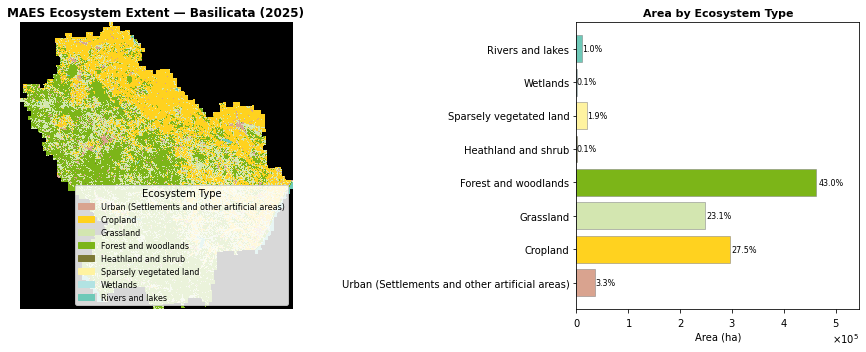

In [26]:
# ── 1e. Visualise MAES extent map ─────────────────────────────────────────────
rgb, patches = make_maes_rgb(maes_arr, extent_table)

fig, (ax_map, ax_bar) = plt.subplots(
    1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]}
)

ax_map.imshow(rgb, interpolation="nearest")
ax_map.set_title(
    f"MAES Ecosystem Extent — {LIVING_SPACE} ({ACCOUNTING_YEAR})",
    fontsize=12, fontweight="bold"
)
ax_map.legend(handles=patches, loc="lower right", fontsize=8,
              title="Ecosystem Type", framealpha=0.85)
ax_map.axis("off")

bar_colours = [p.get_facecolor() for p in patches]
bars = ax_bar.barh(
    extent_table["ecosystem_type"], extent_table["area_ha"],
    color=bar_colours, edgecolor="grey", linewidth=0.5
)
ax_bar.set_xlabel("Area (ha)", fontsize=10)
ax_bar.set_title("Area by Ecosystem Type", fontsize=11, fontweight="bold")
ax_bar.xaxis.set_major_formatter(ScalarFormatter(useMathText=True))
ax_bar.xaxis.get_major_formatter().set_powerlimits((0, 0))
for bar, pct in zip(bars, extent_table["area_pct"]):
    ax_bar.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
                f"{pct:.1f}%", va="center", fontsize=8)
ax_bar.margins(x=0.18)

plt.tight_layout()
save_fig(fig, OUTPUT_DIR / f"fig1_maes_extent_map_{ACCOUNTING_YEAR}.png")
plt.show()

---
## Step 2 — Verify and Align the InVEST Service Rasters

**D3.5 §4.1.1.2**

Each service defined in `SERVICES` is checked for existence, CRS, shape and resolution and, when it differs from the
MAES grid, re-gridded (`ALIGN_SERVICES = True`).  Services given as a list of rasters (e.g. one per pollinator guild)
are combined pixel-wise.  This implements the §4.1.2 requirement:
*'Maintain consistent spatial resolution between MAES and InVEST outputs.'*

In [27]:
ALIGNED_DIR = OUTPUT_DIR / "_aligned_services"
ALIGNED_DIR.mkdir(exist_ok=True)

service_arrays = {}   # svc → 2-D float32 array on the MAES grid (NaN = missing)
service_info   = {}   # svc → metadata dict

print(f"Verifying InVEST rasters (MAES reference: {maes_res:.1f} m, {maes_crs})\n")

for svc, spec in SERVICES.items():
    paths = spec["path"] if isinstance(spec["path"], (list, tuple)) else [spec["path"]]
    paths = [Path(p) for p in paths]
    if not paths or any(not p.exists() for p in paths):
        gone = [str(p) for p in paths if not p.exists()] or ["(no file found)"]
        print(f"  ⚠️  {svc}: NOT FOUND → {', '.join(gone)}\n")
        continue

    layers, infos = [], []
    for k, p in enumerate(paths):
        arr, info = load_aligned_layer(p, spec["basis"], f"{svc}_{k}")
        layers.append(arr); infos.append(info)

    if len(layers) == 1:
        combined = layers[0]
    else:
        stack = np.stack(layers)
        how = spec.get("combine", "mean" if spec["basis"] == "index" else "sum")
        combined = (np.nanmean(stack, axis=0) if how == "mean"
                    else np.where(np.all(np.isnan(stack), axis=0), np.nan, np.nansum(stack, axis=0)))
        combined = combined.astype(np.float32)

    valid = combined[~np.isnan(combined) & ~excl_mask]
    service_arrays[svc] = combined
    service_info[svc] = {
        "n_files": len(paths), "layers": infos,
        "same_grid": all(i["same_grid"] for i in infos), "aligned": any(i["aligned"] for i in infos),
        "n_valid": int(valid.size),
        "min": float(valid.min()) if valid.size else np.nan,
        "max": float(valid.max()) if valid.size else np.nan,
        "mean": float(valid.mean()) if valid.size else np.nan,
    }
    tag = ("re-gridded → MAES grid" if service_info[svc]["aligned"] else "already on MAES grid")
    info = service_info[svc]
    print(f"  ✅ {svc}  ({spec['label']})")
    print(f"     Files      : {info['n_files']}  |  {tag}  |  basis = {spec['basis']}, kind = {spec['kind']}")
    print(f"     Range      : [{info['min']:.4f}, {info['max']:.4f}]  mean = {info['mean']:.4f} {spec['unit']}\n")

assert service_arrays, "No service raster could be loaded — check SERVICES."
print(f"{len(service_arrays)}/{len(SERVICES)} service rasters ready.")

Verifying InVEST rasters (MAES reference: 10.0 m, EPSG:6875)

  ✅ carbon_storage  (Carbon storage)
     Files      : 1  |  already on MAES grid  |  basis = per_ha, kind = stock
     Range      : [0.0000, 309.0000]  mean = 118.8123 Mg C ha⁻¹

  ✅ sediment_avoided_export  (Sediment retention (avoided export))
     Files      : 1  |  already on MAES grid  |  basis = per_ha, kind = flow
     Range      : [0.0033, 69748.7812]  mean = 15.7521 t ha⁻¹ yr⁻¹

  ✅ n_total_export  (Nitrogen export)
     Files      : 1  |  already on MAES grid  |  basis = per_ha, kind = pressure
     Range      : [0.0000, 32.4711]  mean = 2.9748 kg ha⁻¹ yr⁻¹

  ✅ habitat_quality  (Habitat quality)
     Files      : 1  |  already on MAES grid  |  basis = index, kind = index
     Range      : [0.0000, 1.0000]  mean = 0.6392 index (0–1)

  ✅ pollinator_supply  (Pollinator supply (mean of guilds))
     Files      : 3  |  already on MAES grid  |  basis = index, kind = index
     Range      : [0.0000, 0.1001]  mean = 0.0

---
## Step 3 — Spatial Overlay and Attribution

**D3.5 §4.1.1.3**

For each MAES ecosystem type $i$ and each service $s$ the pixel values are aggregated according to the unit basis of the service:

| Basis | Raster values | Total$_{i,s}$ | Mean$_{i,s}$ |
|---|---|---|---|
| `per_ha` | density per hectare | $\sum_{p \in i} S_{p,s} \times A_p$ (D3.5 Eq. 4.1.1.3) | $\overline{S}_{i,s}$ |
| `per_pixel` | amount per pixel | $\sum_{p \in i} S_{p,s}$ | $\sum S_{p,s} / \sum A_p$ (per ha) |
| `depth_mm` | depth in mm | $\sum_{p \in i} S_{p,s} \times 10 \times A_p$ (m³) | $\overline{S}_{i,s}$ |
| `index` | dimensionless index | *not defined* | $\overline{S}_{i,s}$ |

$A_p$ is the pixel area in hectares.  Missing pixels are ignored; `pct_valid_<service>` reports the share of the ecosystem type
that actually has a value, and totals refer to the valid pixels only.

In [28]:
print("Running zonal statistics...\n")
all_zonal = {}   # svc → DataFrame

for svc, svc_arr in service_arrays.items():
    df = zonal_service_stats(
        maes_arr=maes_arr, svc_arr=svc_arr, svc_name=svc, basis=SERVICES[svc]["basis"],
        pixel_ha=pix_ha, unique_codes=unique_codes, excl_mask=excl_mask,
    )
    df["ecosystem_type"] = df["maes_code"].map(code_to_name).fillna("Unknown")
    all_zonal[svc] = df
    print(f"  ✅ {svc}")

print("\nZonal overlay complete.")

Running zonal statistics...

  ✅ carbon_storage
  ✅ sediment_avoided_export
  ✅ n_total_export
  ✅ habitat_quality
  ✅ pollinator_supply

Zonal overlay complete.


---
## Step 4 — Physical Supply Table (SEEA-EA)

**D3.5 §4.1.1.4**

Zonal results for all services are merged into a single wide **Physical Supply Table**
(Table 3 of D3.5) — the core SEEA-EA output of this notebook.  For every service the table reports the mean value per
ecosystem type, its standard deviation and coefficient of variation (a first indication of uncertainty), the share of valid pixels, and
— where physically meaningful — the total supply.

In [29]:
# ── 4a. Build the Physical Supply Table ───────────────────────────────────────
supply_table = extent_table[["maes_code", "ecosystem_type", "area_ha"]].copy()
for svc, zdf in all_zonal.items():
    keep = ["maes_code", f"pct_valid_{svc}", f"mean_{svc}", f"std_{svc}", f"cv_{svc}", f"total_{svc}"]
    supply_table = supply_table.merge(zdf[keep], on="maes_code", how="left")

# Share of each ecosystem type in the grand total of additive services
for svc in all_zonal:
    if is_additive(SERVICES[svc]):
        tot = supply_table[f"total_{svc}"].sum()
        supply_table[f"share_pct_{svc}"] = (supply_table[f"total_{svc}"] / tot * 100).round(2) if tot else np.nan

# Service metadata (units and aggregation rule of every column)
service_meta = pd.DataFrame([{
    "service": svc, "label": s["label"], "kind": s["kind"], "basis": s["basis"],
    "unit_values": s["unit"], "unit_mean": density_unit(s), "unit_total": s["unit_total"] or "– (index, no total)",
    "group": s["group"], "model_year": s["year"],
} for svc, s in SERVICES.items() if svc in service_arrays])

display_cols = (["maes_code", "ecosystem_type", "area_ha"] +
                [c for c in supply_table.columns if c.startswith(("mean_", "total_"))])
print("📋 Table 3 — SEEA-EA Physical Supply Table:")
display(supply_table[display_cols])
print("\nUnits and aggregation rules:")
display(service_meta)

out_t3 = OUTPUT_DIR / f"table3_physical_supply_table_{ACCOUNTING_YEAR}.csv"
supply_table.to_csv(out_t3, index=False)
service_meta.to_csv(OUTPUT_DIR / f"table_service_metadata_{ACCOUNTING_YEAR}.csv", index=False)
print(f"Saved → {out_t3.name}")

📋 Table 3 — SEEA-EA Physical Supply Table:


,maes_code,ecosystem_type,area_ha,mean_carbon_storage,total_carbon_storage,mean_sediment_avoided_export,total_sediment_avoided_export,mean_n_total_export,total_n_total_export,mean_habitat_quality,total_habitat_quality,mean_pollinator_supply,total_pollinator_supply
0,101,Urban (Settlements and other artificial areas),35706.77,13.0,4.641880e+05,12.388249,3.200759e+05,2.094184,6.954730e+04,0.000000,NaN,0.005360,NaN
1,102,Cropland,295390.02,44.0,1.299716e+07,15.743731,4.364118e+06,8.900381,2.493570e+06,0.018879,NaN,0.007300,NaN
2,103,Grassland,248469.16,82.0,2.037447e+07,19.789263,4.640620e+06,1.094788,2.605470e+05,0.800000,NaN,0.052765,NaN
3,104,Forest and woodlands,461952.31,202.0,9.331436e+07,13.741798,6.045824e+06,0.447118,1.983287e+05,1.000000,NaN,0.064917,NaN
4,105,Heathland and shrub,931.22,83.0,7.729126e+04,16.557861,1.078546e+04,0.673240,4.782156e+02,0.900000,NaN,0.053479,NaN
5,106,Sparsely vegetated land,20125.81,6.0,1.207549e+05,16.991903,3.075215e+05,0.232039,4.346541e+03,0.500000,NaN,0.044290,NaN
6,107,Wetlands,886.24,309.0,2.738482e+05,23.785620,3.866352e+03,0.143013,5.153740e+01,1.000000,NaN,0.013999,NaN
7,200,Rivers and lakes,10687.16,0.0,0.000000e+00,24.654123,7.507920e+03,0.000000,0.000000e+00,0.800000,NaN,0.000000,NaN



Units and aggregation rules:


,service,label,kind,basis,unit_values,unit_mean,unit_total,group,model_year
0,carbon_storage,Carbon storage,stock,per_ha,Mg C ha⁻¹,Mg C ha⁻¹,Mg C,carbon,2024
1,sediment_avoided_export,Sediment retention (avoided export),flow,per_ha,t ha⁻¹ yr⁻¹,t ha⁻¹ yr⁻¹,t yr⁻¹,sediment,2024
2,n_total_export,Nitrogen export,pressure,per_ha,kg ha⁻¹ yr⁻¹,kg ha⁻¹ yr⁻¹,kg yr⁻¹,nutrient,2024
3,habitat_quality,Habitat quality,index,index,index (0–1),index (0–1),"– (index, no total)",habitat,2024
4,pollinator_supply,Pollinator supply (mean of guilds),index,index,index (0–1),index (0–1),"– (index, no total)",pollination,2024


Saved → table3_physical_supply_table_2025.csv


   Figure saved → fig2_supply_per_ecosystem_2025.png


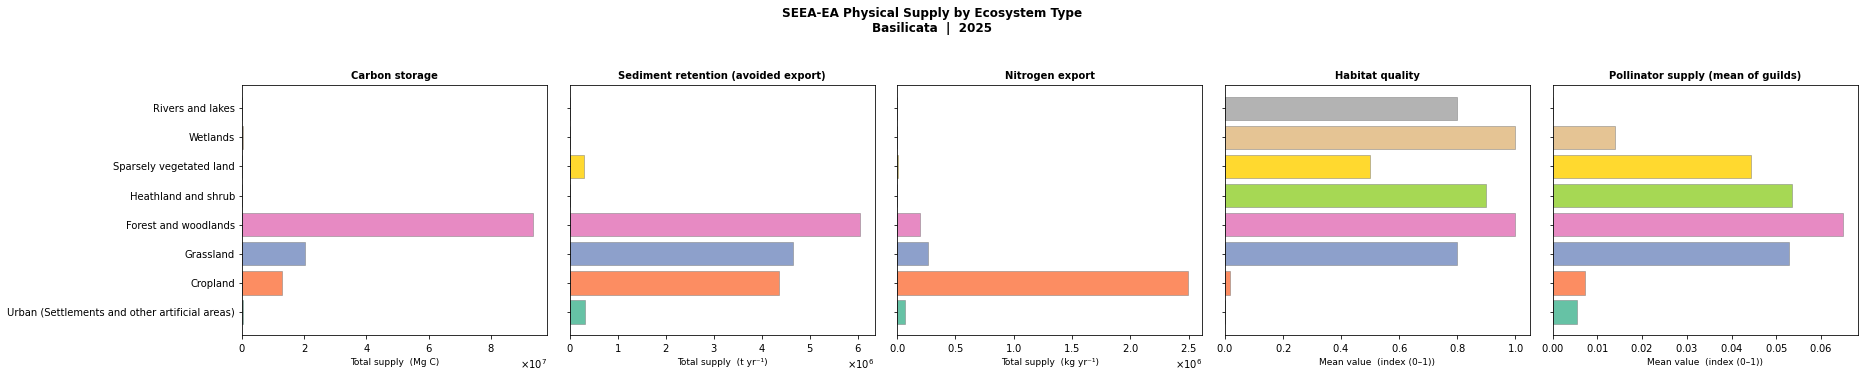

In [30]:
# ── 4b. Bar charts — supply per ecosystem type ────────────────────────────────
# Additive services: total supply.  Indices: mean value (a total is not meaningful).
svc_list = list(all_zonal)
n_svc = len(svc_list)
fig, axes = plt.subplots(1, n_svc, figsize=(5.2 * n_svc, 5), squeeze=False)
bar_pal = get_cmap_n("Set2", max(len(supply_table), 1))

for idx, svc in enumerate(svc_list):
    ax, spec = axes[0][idx], SERVICES[svc]
    col = f"total_{svc}" if is_additive(spec) else f"mean_{svc}"
    sub = supply_table[["ecosystem_type", col]].dropna()
    ax.barh(sub["ecosystem_type"], sub[col], color=[bar_pal(i) for i in range(len(sub))],
            edgecolor="grey", linewidth=0.5)
    ax.set_xlabel(f"Total supply  ({spec['unit_total']})" if is_additive(spec)
                  else f"Mean value  ({spec['unit']})", fontsize=9)
    ax.set_title(spec["label"], fontsize=10, fontweight="bold")
    ax.xaxis.set_major_formatter(ScalarFormatter(useMathText=True))
    ax.xaxis.get_major_formatter().set_powerlimits((-3, 4))
    if idx > 0:
        ax.set_yticklabels([])

plt.suptitle(f"SEEA-EA Physical Supply by Ecosystem Type\n{LIVING_SPACE}  |  {ACCOUNTING_YEAR}",
             fontsize=12, fontweight="bold", y=1.04)
plt.tight_layout()
save_fig(fig, OUTPUT_DIR / f"fig2_supply_per_ecosystem_{ACCOUNTING_YEAR}.png")
plt.show()

   Figure saved → fig3_supply_share_pies_2025.png


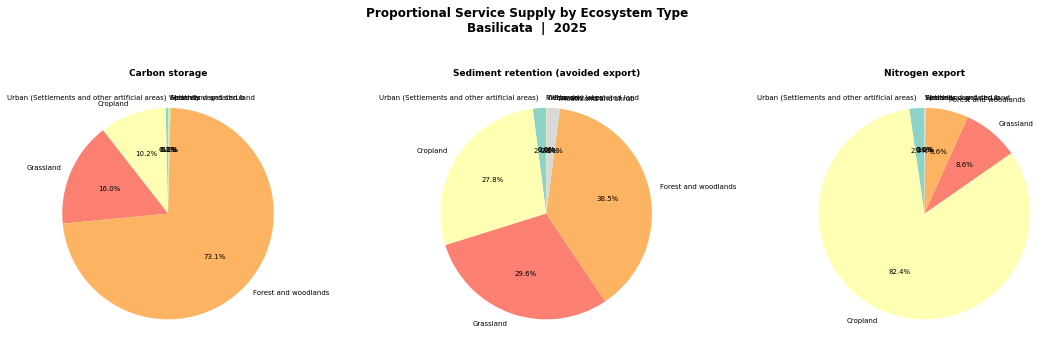

In [31]:
# ── 4c. Pie charts — % share of total supply (additive services only) ────────
add_svcs = [s for s in all_zonal if is_additive(SERVICES[s])]
if add_svcs:
    fig, axes = plt.subplots(1, len(add_svcs), figsize=(5 * len(add_svcs), 5), squeeze=False)
    pie_pal = get_cmap_n("Set3", max(len(supply_table), 1))
    for idx, svc in enumerate(add_svcs):
        ax = axes[0][idx]
        sub = supply_table[["ecosystem_type", f"total_{svc}"]].dropna()
        sub = sub[sub[f"total_{svc}"] > 0]
        ax.pie(sub[f"total_{svc}"], labels=sub["ecosystem_type"],
               colors=[pie_pal(i) for i in range(len(sub))],
               autopct="%1.1f%%", startangle=90, textprops={"fontsize": 7})
        ax.set_title(SERVICES[svc]["label"], fontsize=9, fontweight="bold")
    plt.suptitle(f"Proportional Service Supply by Ecosystem Type\n{LIVING_SPACE}  |  {ACCOUNTING_YEAR}",
                 fontsize=12, fontweight="bold", y=1.02)
    plt.tight_layout()
    save_fig(fig, OUTPUT_DIR / f"fig3_supply_share_pies_{ACCOUNTING_YEAR}.png")
    plt.show()
else:
    print("No additive service — pie charts skipped.")

   Figure saved → fig4_1_carbon_storage_2025.png


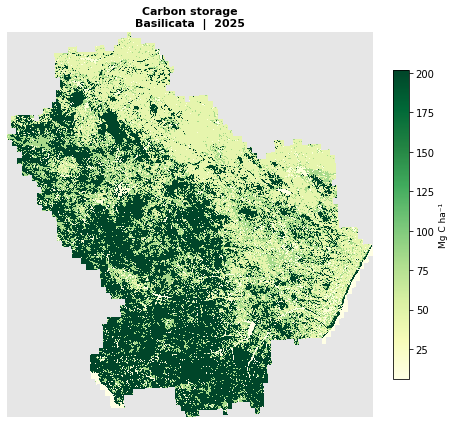

   GeoTIFF saved → service_carbon_storage_2025.tif
   Figure saved → fig4_2_sediment_avoided_export_2025.png


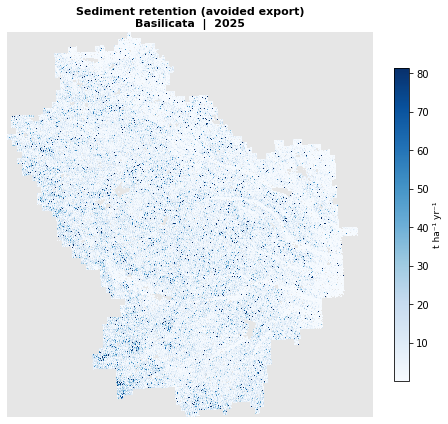

   GeoTIFF saved → service_sediment_avoided_export_2025.tif
   Figure saved → fig4_3_n_total_export_2025.png


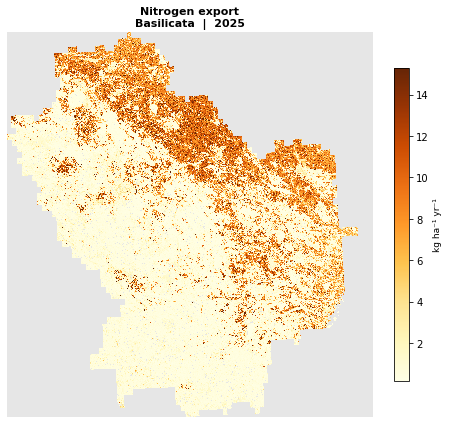

   GeoTIFF saved → service_n_total_export_2025.tif
   Figure saved → fig4_4_habitat_quality_2025.png


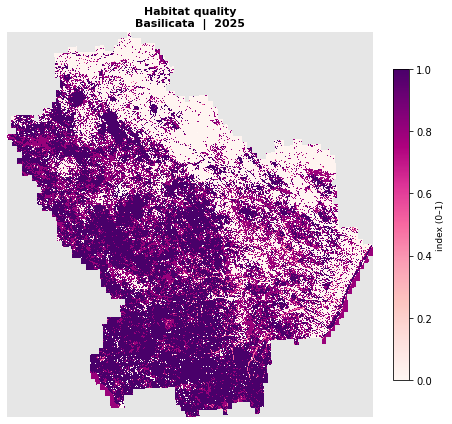

   GeoTIFF saved → service_habitat_quality_2025.tif
   Figure saved → fig4_5_pollinator_supply_2025.png


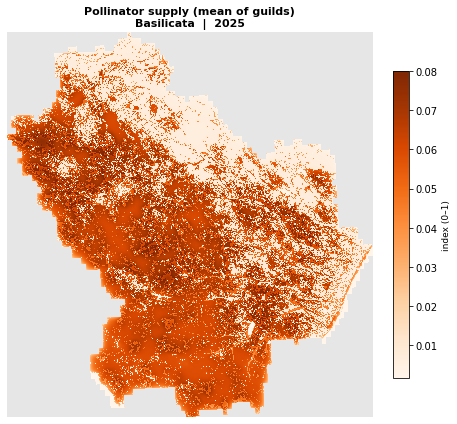

   GeoTIFF saved → service_pollinator_supply_2025.tif
   GeoTIFF saved → ecosystem_services_by_type_2025.tif
   GeoTIFF saved → ecosystem_services_supply_per_pixel_2025.tif
   ✅ carbon_storage: raster sum 127,622,070.22  vs  Table 3 total 127,622,075.27
   ✅ sediment_avoided_export: raster sum 15,700,317.89  vs  Table 3 total 15,700,318.17
   ✅ n_total_export: raster sum 3,026,869.47  vs  Table 3 total 3,026,869.54


In [32]:
# ── 4d. Spatial maps — one per service ───────────────────────────────────────
cmaps = ["YlGn", "Blues", "YlOrBr", "RdPu", "Oranges", "PuBuGn"]

for i, (svc, svc_arr) in enumerate(service_arrays.items()):
    spec = SERVICES[svc]
    shown = np.where(excl_mask, np.nan, svc_arr)
    finite = shown[~np.isnan(shown)]
    vmin, vmax = (np.percentile(finite, [1, 99]) if finite.size else (0, 1))
    cmap = get_cmap_n(cmaps[i % len(cmaps)]).copy()
    cmap.set_bad("#e6e6e6")

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(np.ma.masked_invalid(shown), cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    plt.colorbar(im, ax=ax, fraction=0.03, pad=0.04).set_label(spec["unit"], fontsize=9)
    ax.set_title(f"{spec['label']}\n{LIVING_SPACE}  |  {ACCOUNTING_YEAR}", fontsize=11, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    save_fig(fig, OUTPUT_DIR / f"fig4_{i+1}_{svc}_{ACCOUNTING_YEAR}.png")
    plt.show()
    write_geotiff(shown, OUTPUT_DIR / f"service_{svc}_{ACCOUNTING_YEAR}.tif",
                  descriptions=[spec["label"]],
                  tags={"service": svc, "unit": spec["unit"], "basis": spec["basis"], "kind": spec["kind"],
                        "model_year": spec["year"], "nodata_meaning": "missing value or outside the MAES extent"})


# ── 4e. Multiband GeoTIFF: MEAN service density by ecosystem type (MAES grid) ─────
# One band per service.  Every pixel carries the mean of its ecosystem type (area-weighted over valid
# pixels), always as a DENSITY (never a per-pixel amount) — so summing this raster does NOT give the
# Table 3 totals; use the Table 3 CSV for totals.
bands, descs, btags = [], [], []
for svc in all_zonal:
    spec = SERVICES[svc]
    band = np.full(maes_arr.shape, np.nan, dtype=np.float32)
    for code, val in zip(supply_table["maes_code"], supply_table[f"mean_{svc}"]):
        if pd.notna(val):
            band[(maes_arr == code) & (~excl_mask)] = val
    bands.append(band); descs.append(spec["label"])
    btags.append({"service": svc, "unit": density_unit(spec), "basis": spec["basis"], "kind": spec["kind"],
                  "model_year": spec["year"]})
write_geotiff(np.stack(bands), OUTPUT_DIR / f"ecosystem_services_by_type_{ACCOUNTING_YEAR}.tif",
              descriptions=descs, band_tags=btags,
              tags={"product": "Mean ecosystem service density by MAES ecosystem type",
                    "living_space": LIVING_SPACE, "accounting_year": ACCOUNTING_YEAR,
                    "nodata_meaning": "ecosystem type without valid service values, or outside the MAES extent",
                    "note": "values are means (densities); do not sum across pixels",
                    "source": "LandShift D3.5 section 4.1"})



# ── 4f. Multiband GeoTIFF: PER-PIXEL supply by ecosystem type (additive services only) ──
# The Table 3 total of each ecosystem type is spread evenly over the pixels of that type, so the sum of a
# band over the whole raster equals the Table 3 total (for fully valid types this is mean density × pixel
# area).  Indices have no total and are not included.  Values depend on the pixel size (see tags).
pp_bands, pp_desc, pp_tags, perpixel_check = [], [], [], {}
for svc in all_zonal:
    spec = SERVICES[svc]
    if not is_additive(spec):
        continue
    band = np.full(maes_arr.shape, np.nan, dtype=np.float32)
    for code, tot in zip(supply_table["maes_code"], supply_table[f"total_{svc}"]):
        zone = (maes_arr == code) & (~excl_mask)
        if pd.notna(tot) and zone.any():
            band[zone] = tot / zone.sum()
    pp_bands.append(band); pp_desc.append(spec["label"])
    pp_tags.append({"service": svc, "unit": f"{spec['unit_total']} per pixel", "basis": spec["basis"],
                    "kind": spec["kind"], "model_year": spec["year"], "pixel_area_ha": round(pix_ha, 6)})
    perpixel_check[svc] = (float(np.nansum(band.astype(np.float64))), float(supply_table[f"total_{svc}"].sum()))

if pp_bands:
    write_geotiff(np.stack(pp_bands), OUTPUT_DIR / f"ecosystem_services_supply_per_pixel_{ACCOUNTING_YEAR}.tif",
                  descriptions=pp_desc, band_tags=pp_tags,
                  tags={"product": "Per-pixel ecosystem service supply by MAES ecosystem type",
                        "living_space": LIVING_SPACE, "accounting_year": ACCOUNTING_YEAR,
                        "pixel_area_ha": round(pix_ha, 6),
                        "nodata_meaning": "ecosystem type without valid service values, or outside the MAES extent",
                        "note": "band sum over the raster = Table 3 total; values depend on the pixel size",
                        "source": "LandShift D3.5 section 4.1"})
    for svc, (raster_sum, table_total) in perpixel_check.items():
        ok = np.isclose(raster_sum, table_total, rtol=1e-4)
        print(f"   {'✅' if ok else '⚠️ '} {svc}: raster sum {raster_sum:,.2f}  vs  Table 3 total {table_total:,.2f}")
else:
    print("No additive service — per-pixel supply GeoTIFF skipped.")


---
## Step 5 (Optional) — Linking to Ecosystem Condition

**D3.5 §4.1.1.5**

When the SEEA-EA condition raster of the WP3 workflow is available (it replaces the former ESAI layer), every pixel is assigned to
one of the three condition classes of D3.5 and service supply is stratified by ecosystem type **and** condition class:

| Class | SEEA-EA score | Meaning |
|---|---|---|
| **Good** | 4–5 | Good / Very Good condition |
| **Moderate** | 3 | Fair condition |
| **Degraded** | 1–2 | Poor / Very Poor condition |
| *Not assessed* | NoData | Not scored upstream (e.g. cropland, urban, water) or missing pixel |

The *Not assessed* class is kept so that the stratified totals always add up to Table 3.
The condition raster is categorical and is therefore re-gridded with **nearest neighbour** when needed.
For each ecosystem type the ratio of mean supply in Degraded vs Good areas is also reported (the
D3.5 example: high-condition forest 3.0 vs degraded forest 1.5 Mg C ha⁻¹ yr⁻¹).

> ⚠️ The ratio is a spatial comparison, not a causal effect: degraded and good areas can differ in elevation, soil
> or management as well.

In [33]:
run_step5 = (CONDITION_RASTER is not None) and Path(CONDITION_RASTER).exists()
stratified_df, effect_df, cond_info = None, None, None

if run_step5:
    cond_raw, cond_info = load_aligned_layer(CONDITION_RASTER, "index", "condition",
                                             resampling=Resampling.nearest)
    ok = ~np.isnan(cond_raw) & np.isin(cond_raw, list(SEEA_TO_CLASS))
    n_invalid_cond = int((~np.isnan(cond_raw) & ~ok).sum())
    cond_arr = np.where(ok, cond_raw, np.nan).astype(np.float32)

    cond_code = np.zeros(cond_arr.shape, dtype=np.uint8)           # 0 = Not assessed
    for score, cls in SEEA_TO_CLASS.items():
        cond_code[cond_arr == score] = CLASS_CODE[cls]

    mapped = ~excl_mask
    print("Condition class distribution (mapped area):")
    for cls in CLASS_ORDER:
        n = int(((cond_code == CLASS_CODE[cls]) & mapped).sum())
        print(f"  {cls:<13}: {n:>9,} px  ({n / mapped.sum() * 100:5.1f} %)  {n * pix_ha:>12,.1f} ha")
    if n_invalid_cond:
        print(f"  ⚠️  {n_invalid_cond:,} pixel(s) outside the valid scores 1–5 were treated as Not assessed")

    # ── Stratified supply: ecosystem type × condition class ───────────────────
    rows = []
    for code in unique_codes:
        zone = (maes_arr == code) & mapped
        n_zone = int(zone.sum())
        for cls in CLASS_ORDER:
            cmask = zone & (cond_code == CLASS_CODE[cls])
            n_pix = int(cmask.sum())
            if n_pix == 0:
                continue
            rec = {"maes_code": int(code), "ecosystem_type": code_to_name.get(int(code), "Unknown"),
                   "condition_class": cls, "pixel_count": n_pix,
                   "area_ha": round(n_pix * pix_ha, 4),
                   "pct_of_type": round(n_pix / n_zone * 100, 2)}
            for svc, svc_arr in service_arrays.items():
                agg = aggregate_values(svc_arr[cmask], SERVICES[svc]["basis"], pix_ha)
                rec[f"mean_{svc}"]  = round(agg["mean"], 6)  if pd.notna(agg["mean"])  else np.nan
                rec[f"total_{svc}"] = round(agg["total"], 4) if pd.notna(agg["total"]) else np.nan
            rows.append(rec)
    stratified_df = pd.DataFrame(rows)

    print("\n📋 Supply by Ecosystem Type × Condition Class:")
    display(stratified_df[["ecosystem_type", "condition_class", "area_ha", "pct_of_type"] +
                          [c for c in stratified_df.columns if c.startswith("mean_")]])
    out_cond = OUTPUT_DIR / f"table_supply_by_condition_{ACCOUNTING_YEAR}.csv"
    stratified_df.to_csv(out_cond, index=False)
    print(f"Saved → {out_cond.name}")

    # ── Degraded / Good ratio of mean supply ──────────────────────────────────
    eff = []
    for code in unique_codes:
        sub = stratified_df[stratified_df["maes_code"] == code].set_index("condition_class")
        if not {"Good", "Degraded"} <= set(sub.index):
            continue
        if min(sub.loc["Good", "pixel_count"], sub.loc["Degraded", "pixel_count"]) < MIN_PIXELS_FOR_RATIO:
            continue
        rec = {"maes_code": int(code), "ecosystem_type": code_to_name.get(int(code), "Unknown")}
        for svc in service_arrays:
            g, d = sub.loc["Good", f"mean_{svc}"], sub.loc["Degraded", f"mean_{svc}"]
            rec[f"mean_good_{svc}"], rec[f"mean_degraded_{svc}"] = g, d
            rec[f"ratio_degraded_to_good_{svc}"] = round(d / g, 3) if pd.notna(g) and g > 0 else np.nan
        eff.append(rec)
    effect_df = pd.DataFrame(eff)
    if not effect_df.empty:
        print("\n📋 Mean supply in Degraded vs Good areas (ratio < 1 = lower supply where degraded;"
              " for pressure services such as nutrient export, ratio > 1 = higher export):")
        display(effect_df[["ecosystem_type"] + [c for c in effect_df.columns if c.startswith("ratio_")]])
        effect_df.to_csv(OUTPUT_DIR / f"table_condition_effect_{ACCOUNTING_YEAR}.csv", index=False)
    else:
        print(f"\nℹ️  No ecosystem type has ≥ {MIN_PIXELS_FOR_RATIO} pixels in both Good and Degraded condition.")
else:
    print("ℹ️  Condition raster not provided or not found — Step 5 skipped.")

Condition class distribution (mapped area):
  Good         : 30,328,497 px  ( 28.2 %)     303,285.0 ha
  Moderate     : 11,651,027 px  ( 10.8 %)     116,510.3 ha
  Degraded     :   255,154 px  (  0.2 %)       2,551.5 ha
  Not assessed : 65,180,191 px  ( 60.7 %)     651,801.9 ha

📋 Supply by Ecosystem Type × Condition Class:


,ecosystem_type,condition_class,area_ha,pct_of_type,mean_carbon_storage,mean_sediment_avoided_export,mean_n_total_export,mean_habitat_quality,mean_pollinator_supply
0,Urban (Settlements and other artificial areas),Not assessed,35706.77,100.00,13.000000,12.388249,2.094184,0.000000,0.005360
1,Cropland,Not assessed,295390.02,100.00,44.000000,15.743731,8.900381,0.018879,0.007300
2,Grassland,Good,19513.56,7.85,82.000008,21.849474,1.145354,0.800000,0.050914
3,Grassland,Moderate,7763.39,3.12,82.000000,22.284611,1.120067,0.800000,0.050202
4,Grassland,Degraded,43.76,0.02,82.000000,27.675459,1.118559,0.800000,0.047840
5,Grassland,Not assessed,221148.45,89.00,82.000000,19.521137,1.089477,0.800000,0.053020
6,Forest and woodlands,Good,278957.84,60.39,202.000015,11.828444,0.459904,1.000000,0.063614
7,Forest and woodlands,Moderate,93281.38,20.19,202.000000,15.924324,0.429393,1.000000,0.066366
8,Forest and woodlands,Degraded,2213.25,0.48,201.999985,16.226240,0.431825,1.000000,0.064914
9,Forest and woodlands,Not assessed,87499.84,18.94,202.000000,17.565765,0.425215,1.000000,0.067525


Saved → table_supply_by_condition_2025.csv

📋 Mean supply in Degraded vs Good areas (ratio < 1 = lower supply where degraded; for pressure services such as nutrient export, ratio > 1 = higher export):


,ecosystem_type,ratio_degraded_to_good_carbon_storage,ratio_degraded_to_good_sediment_avoided_export,ratio_degraded_to_good_n_total_export,ratio_degraded_to_good_habitat_quality,ratio_degraded_to_good_pollinator_supply
0,Grassland,1.0,1.267,0.977,1.0,0.940
1,Forest and woodlands,1.0,1.372,0.939,1.0,1.020
2,Heathland and shrub,1.0,1.212,1.040,1.0,0.990
3,Sparsely vegetated land,1.0,1.146,0.815,1.0,0.920
4,Wetlands,1.0,0.565,1.342,1.0,1.247


   Figure saved → fig5_supply_by_condition_2025.png


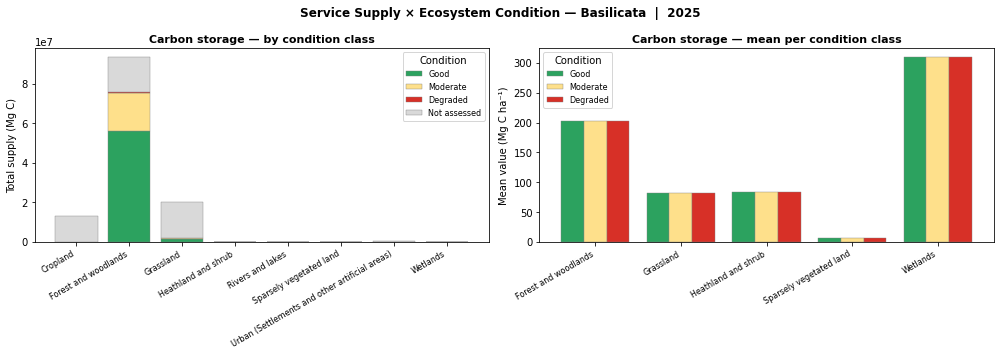

   Figure saved → fig6_condition_map_2025.png


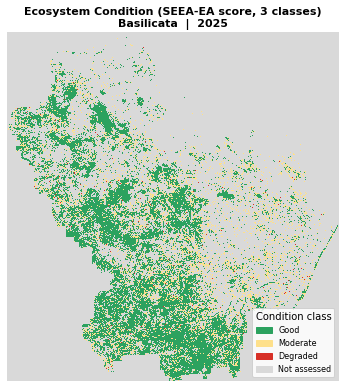

   GeoTIFF saved → condition_class_2025.tif


In [34]:
if run_step5 and stratified_df is not None and not stratified_df.empty:
    add_svcs = [s for s in service_arrays if is_additive(SERVICES[s])]
    focus = FOCUS_SERVICE if FOCUS_SERVICE in service_arrays else (add_svcs[0] if add_svcs else list(service_arrays)[0])
    spec  = SERVICES[focus]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # (a) stacked totals by condition class (additive) or area (index)
    if is_additive(spec):
        val_col, ylabel = f"total_{focus}", f"Total supply ({spec['unit_total']})"
    else:
        val_col, ylabel = "area_ha", "Area (ha)"
    pivot = stratified_df.pivot_table(index="ecosystem_type", columns="condition_class",
                                      values=val_col, aggfunc="sum", fill_value=0)
    pivot = pivot.reindex(columns=[c for c in CLASS_ORDER if c in pivot.columns])
    bottom = np.zeros(len(pivot))
    for cls in pivot.columns:
        ax1.bar(pivot.index, pivot[cls].values, bottom=bottom, label=cls,
                color=CLASS_COLOURS[cls], edgecolor="grey", linewidth=0.4)
        bottom += pivot[cls].values
    ax1.set_ylabel(ylabel, fontsize=10)
    ax1.set_title(f"{spec['label']} — by condition class", fontsize=11, fontweight="bold")
    ax1.legend(title="Condition", fontsize=8)
    ax1.tick_params(axis="x", rotation=30, labelsize=8)
    for lab in ax1.get_xticklabels():
        lab.set_ha("right")

    # (b) mean value per class (assessed classes only)
    mean_piv = stratified_df[stratified_df["condition_class"] != "Not assessed"].pivot_table(
        index="ecosystem_type", columns="condition_class", values=f"mean_{focus}")
    mean_piv = mean_piv.reindex(columns=[c for c in CLASS_ORDER[:3] if c in mean_piv.columns])
    if not mean_piv.empty:
        mean_piv.plot.bar(ax=ax2, color=[CLASS_COLOURS[c] for c in mean_piv.columns],
                          edgecolor="grey", linewidth=0.4, width=0.8)
        ax2.set_ylabel(f"Mean value ({density_unit(spec)})", fontsize=10)
        ax2.set_xlabel("")
        ax2.legend(title="Condition", fontsize=8)
        ax2.tick_params(axis="x", rotation=30, labelsize=8)
        for lab in ax2.get_xticklabels():
            lab.set_ha("right")
    ax2.set_title(f"{spec['label']} — mean per condition class", fontsize=11, fontweight="bold")

    plt.suptitle(f"Service Supply × Ecosystem Condition — {LIVING_SPACE}  |  {ACCOUNTING_YEAR}",
                 fontsize=12, fontweight="bold")
    plt.tight_layout()
    save_fig(fig, OUTPUT_DIR / f"fig5_supply_by_condition_{ACCOUNTING_YEAR}.png")
    plt.show()

    # ── Condition class map ───────────────────────────────────────────────────
    rgb_c = np.empty((*cond_code.shape, 3)); rgb_c[:] = mcolors.to_rgb(CLASS_COLOURS["Not assessed"])
    for cls in CLASS_ORDER[:3]:
        rgb_c[cond_code == CLASS_CODE[cls]] = mcolors.to_rgb(CLASS_COLOURS[cls])
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.imshow(rgb_c, interpolation="nearest")
    ax.legend(handles=[mpatches.Patch(color=CLASS_COLOURS[c], label=c) for c in CLASS_ORDER],
              loc="lower right", fontsize=8, title="Condition class", framealpha=0.85)
    ax.set_title(f"Ecosystem Condition (SEEA-EA score, 3 classes)\n{LIVING_SPACE}  |  {CONDITION_YEAR}",
                 fontsize=11, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    save_fig(fig, OUTPUT_DIR / f"fig6_condition_map_{ACCOUNTING_YEAR}.png")
    plt.show()

    # ── Condition class map as GeoTIFF ────────────────────────────────────────
    cls_out = cond_code.copy()
    cls_out[excl_mask] = 255
    write_geotiff(cls_out, OUTPUT_DIR / f"condition_class_{ACCOUNTING_YEAR}.tif", dtype="uint8", nodata=255,
                  descriptions=["Ecosystem condition class"],
                  tags={"values": "3=Good (SEEA-EA 4-5), 2=Moderate (3), 1=Degraded (1-2), 0=Not assessed, 255=outside MAES extent",
                        "condition_year": CONDITION_YEAR, "source": "SEEA-EA condition raster, WP3 workflow"})

---
## Step 6 (Optional) — Monetary Valuation

**D3.5 §4.1.1.6**

$$\text{Monetary Value}_{i,s} = \text{Total Physical Flow}_{i,s} \times \text{Exchange Price}_s$$

> Valuation follows **exchange value principles** consistent with the System of National
> Accounts (SNA). Welfare-based or total-economic-value measures are not used.
> Only services listed in `PRICE_PER_UNIT` are valued, and only if they are **annual flows** (`kind='flow'`) with a physical total:
> - **Stocks** (e.g. carbon storage) are *not* valued with an annual price — SEEA-EA values stocks as ecosystem assets (net present value of future flows).
> - **Indices** have no physical total; **pressures** (e.g. nutrient export) are not services.
>
> The price must refer to the unit of the total *after* `price_factor` (e.g. carbon: price per t CO₂e with `price_factor = 44/12`
> converting Mg C to t CO₂e; D3.5's own example multiplies Mg C by a price per t CO₂e without this conversion).

In [35]:
monetary_table = None
if PRICE_PER_UNIT:
    monetary_table = supply_table[["maes_code", "ecosystem_type", "area_ha"]].copy()
    for svc, price in PRICE_PER_UNIT.items():
        spec = SERVICES.get(svc)
        if spec is None or f"total_{svc}" not in supply_table.columns:
            print(f"  ⚠️  {svc}: not in SERVICES / not loaded — skipped")
            continue
        if spec["kind"] != "flow" or not is_additive(spec):
            why = {"stock": "is a stock, not an annual flow", "pressure": "is a pressure, not a service",
                   "index": "is a dimensionless index"}.get(spec["kind"], "is not an annual flow")
            print(f"  ⚠️  {svc}: NOT valued — {spec['label']} {why}.")
            continue
        factor = spec.get("price_factor", 1.0)
        mc = f"monetary_{svc}_{CURRENCY}"
        monetary_table[mc] = (supply_table[f"total_{svc}"] * factor * price).round(2)
        print(f"  ✅ {svc}: {price} {CURRENCY} per {spec['unit_total']}"
              + (f" (total × {factor:.4f} before pricing)" if factor != 1.0 else ""))

    mon_cols = [c for c in monetary_table.columns if c.startswith("monetary_")]
    if mon_cols:
        print("\n📋 Monetary Valuation Table (SNA exchange-value):")
        display(monetary_table)
        out_mon = OUTPUT_DIR / f"table_monetary_valuation_{ACCOUNTING_YEAR}.csv"
        monetary_table.to_csv(out_mon, index=False)
        print(f"Saved → {out_mon.name}")

        mon_pal = get_cmap_n("Paired", len(mon_cols))
        fig, ax = plt.subplots(figsize=(8, 4))
        bottom = np.zeros(len(monetary_table))
        for j, mc in enumerate(mon_cols):
            vals = monetary_table[mc].fillna(0).values
            ax.bar(monetary_table["ecosystem_type"], vals, bottom=bottom,
                   label=mc.replace("monetary_", "").replace(f"_{CURRENCY}", "").replace("_", " "),
                   color=mon_pal(j), edgecolor="grey", linewidth=0.4)
            bottom += vals
        ax.set_ylabel(f"Monetary value ({CURRENCY})", fontsize=10)
        ax.set_title(f"Monetary Valuation by Ecosystem Type\n{LIVING_SPACE}  |  {ACCOUNTING_YEAR}",
                     fontsize=11, fontweight="bold")
        ax.legend(fontsize=8)
        ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
        ax.yaxis.get_major_formatter().set_powerlimits((0, 0))
        plt.xticks(rotation=30, ha="right", fontsize=9)
        plt.tight_layout()
        save_fig(fig, OUTPUT_DIR / f"fig7_monetary_valuation_{ACCOUNTING_YEAR}.png")
        plt.show()
    else:
        print("\nℹ️  No service could be valued — monetary valuation skipped.")
        monetary_table = None
else:
    print("ℹ️  PRICE_PER_UNIT is empty — monetary valuation skipped.")

ℹ️  PRICE_PER_UNIT is empty — monetary valuation skipped.


---
## Section 7 — Quality Checks

**D3.5 §4.1.2** — *Key Technical Considerations*

Eight checks are run to validate the supply table before SEEA-EA reporting:

1. Spatial consistency (MAES vs. service and condition rasters)
2. Coverage — share of valid service pixels per ecosystem type
3. Physical plausibility (value ranges, negative totals)
4. Temporal alignment between extent, services and condition (§4.1.2: *ensure temporal alignment*)
5. Double-counting guard (overlapping services of the same group, §4.1.2: *avoid double counting*)
6. Reconciliation of the condition-stratified totals with Table 3
7. Accounting year recorded in all output filenames
8. Per-pixel supply GeoTIFF sums to the Table 3 totals

> Uncertainty: standard deviation and coefficient of variation per ecosystem type are reported in Table 3.
> A formal uncertainty / sensitivity analysis (§4.1.2) is not part of this notebook.

In [36]:
print("═" * 65)
print("TECHNICAL QUALITY CHECKS  (D3.5 §4.1.2)")
print("═" * 65)
issues = []

# 1. Spatial consistency
print(f"\n1. Spatial consistency  (MAES reference: {maes_res:.1f} m, {maes_crs})")
checked = dict(service_info)
if cond_info is not None:
    checked["(condition raster)"] = {"layers": [cond_info]}
for name, info in checked.items():
    for lay in info["layers"]:
        if lay["same_grid"]:
            tag = "✅"
        elif lay["aligned"]:
            tag = "↻ re-gridded to the MAES grid"
        else:
            tag = "⚠️  MISMATCH"; issues.append(f"Grid mismatch: {name} / {lay['file']}")
        print(f"   {name:<28} {lay['file']:<34} {lay['res_m']:7.1f} m  {tag}")

# 2. Coverage
print(f"\n2. Valid-pixel coverage per ecosystem type  (threshold {MIN_VALID_PCT:.0f} %)")
cov_issue = False
for svc in all_zonal:
    col = f"pct_valid_{svc}"
    low = supply_table[supply_table[col] < MIN_VALID_PCT]
    for _, r in low.iterrows():
        cov_issue = True
        print(f"   ⚠️  {svc:<26} {r['ecosystem_type']:<32} {r[col]:6.1f} % valid")
        issues.append(f"Low coverage: {svc} in '{r['ecosystem_type']}' ({r[col]:.1f} % valid pixels).")
if not cov_issue:
    print("   ✅ Every ecosystem type has valid service values for ≥ threshold of its area.")
missing_svc = [s for s in SERVICES if s not in service_arrays]
if missing_svc:
    print(f"   ⚠️  Services not loaded: {missing_svc}")
    issues.append(f"Services not loaded: {missing_svc}")

# 3. Plausibility
print("\n3. Physical plausibility")
plaus_ok = True
for svc, arr in service_arrays.items():
    lo, hi = SERVICES[svc].get("valid_range") or (None, None)
    vals = arr[~np.isnan(arr) & ~excl_mask]
    n_lo = int((vals < lo).sum()) if lo is not None else 0
    n_hi = int((vals > hi).sum()) if hi is not None else 0
    if n_lo or n_hi:
        plaus_ok = False
        print(f"   ⚠️  {svc}: {n_lo:,} pixel(s) below {lo}, {n_hi:,} above {hi}")
        issues.append(f"{svc}: values outside the plausible range [{lo}, {hi}].")
for tc in [c for c in supply_table.columns if c.startswith("total_")]:
    if (supply_table[tc] < 0).any():
        plaus_ok = False
        print(f"   ⚠️  {tc}: negative totals"); issues.append(f"Negative totals in {tc}.")
if plaus_ok:
    print("   ✅ All values within the declared ranges; no negative totals.")

# 4. Temporal alignment
print(f"\n4. Temporal alignment with the accounting year ({ACCOUNTING_YEAR})")
years = {svc: SERVICES[svc]["year"] for svc in service_arrays}
if run_step5:
    years["(condition)"] = CONDITION_YEAR
bad_years = {k: y for k, y in years.items() if y != ACCOUNTING_YEAR}
if bad_years:
    print(f"   ⚠️  Different modelling year: {bad_years}")
    issues.append(f"Modelling year differs from the accounting year: {bad_years}.")
else:
    print("   ✅ All layers refer to the accounting year.")

# 5. Double-counting guard
print("\n5. Double-counting guard (services of the same group overlap)")
groups = {}
for svc in service_arrays:
    groups.setdefault(SERVICES[svc]["group"], []).append(svc)
overlap = {g: s for g, s in groups.items() if len(s) > 1}
if overlap:
    for g, s in overlap.items():
        print(f"   ⚠️  Group '{g}': {s} overlap — do not add them up")
        issues.append(f"Overlapping services in group '{g}': {s} (do not sum).")
else:
    print("   ✅ No two services belong to the same group.")

# 6. Condition reconciliation
print("\n6. Condition-stratified totals reconcile with Table 3")
if run_step5 and stratified_df is not None and not stratified_df.empty:
    rec_ok = True
    for svc in service_arrays:
        if not is_additive(SERVICES[svc]):
            continue
        t3 = supply_table[f"total_{svc}"].sum()
        t5 = stratified_df[f"total_{svc}"].sum()
        if not np.isclose(t3, t5, rtol=1e-6, atol=1e-6):
            rec_ok = False
            print(f"   ⚠️  {svc}: Table 3 = {t3:,.4f}  vs  stratified = {t5:,.4f}")
            issues.append(f"Stratified total of {svc} does not reconcile with Table 3.")
    if rec_ok:
        print("   ✅ Stratified totals equal the Table 3 totals.")
else:
    print("   ℹ️  Step 5 not run — check skipped.")

# 7. Year stamp
print(f"\n7. Accounting year ({ACCOUNTING_YEAR}) embedded in all output filenames")
missing_yr = [f.name for f in OUTPUT_DIR.glob("table*.csv") if str(ACCOUNTING_YEAR) not in f.name]
if missing_yr:
    print(f"   ⚠️  Files missing year stamp: {missing_yr}")
    issues.append("Some output files lack the accounting year in their name.")
else:
    print("   ✅ All output CSV files are year-stamped.")

# 8. Per-pixel supply raster
print("\n8. Per-pixel supply GeoTIFF sums to the Table 3 totals")
if perpixel_check:
    pp_ok = True
    for svc, (raster_sum, table_total) in perpixel_check.items():
        if not np.isclose(raster_sum, table_total, rtol=1e-4):
            pp_ok = False
            print(f"   ⚠️  {svc}: raster sum {raster_sum:,.2f} vs Table 3 {table_total:,.2f}")
            issues.append(f"Per-pixel supply raster of {svc} does not sum to the Table 3 total.")
    if pp_ok:
        print("   ✅ Raster sums equal the Table 3 totals.")
else:
    print("   ℹ️  No additive service — check skipped.")

print("\n" + "═" * 65)
if issues:
    print(f"⚠️  {len(issues)} issue(s) require attention:")
    for i, iss in enumerate(issues, 1):
        print(f"   {i}. {iss}")
else:
    print("✅ All checks passed — supply table is ready for SEEA-EA reporting.")
print("═" * 65)

═════════════════════════════════════════════════════════════════
TECHNICAL QUALITY CHECKS  (D3.5 §4.1.2)
═════════════════════════════════════════════════════════════════

1. Spatial consistency  (MAES reference: 10.0 m, EPSG:6875)
   carbon_storage               c_storage_bas.tif                     10.0 m  ✅
   sediment_avoided_export      avoided_export.tif                    10.0 m  ✅
   n_total_export               n_total_export.tif                    10.0 m  ✅
   habitat_quality              quality_c.tif                         10.0 m  ✅
   pollinator_supply            pollinator_supply_bombus_spp.tif      10.0 m  ✅
   pollinator_supply            pollinator_supply_cavity_nesting_solitary_bee.tif    10.0 m  ✅
   pollinator_supply            pollinator_supply_ground_nesting_solitary_bee.tif    10.0 m  ✅
   (condition raster)           ecosystem_condition_map_2025.tif      10.0 m  ✅

2. Valid-pixel coverage per ecosystem type  (threshold 90 %)
   ⚠️  sediment_avoided_export    U

---
## Section 8 — Grand-Total Summary

In [37]:
print("GRAND TOTALS — SEEA-EA Physical Supply Account")
print("-" * 78)
print(f"Living Space    : {LIVING_SPACE}")
print(f"Accounting year : {ACCOUNTING_YEAR}")
print(f"Total area      : {total_area:,.2f} ha  ({total_area/100:,.2f} km²)")
print(f"Ecosystem types : {len(extent_table)}")
print()
print(f"  {'Service':<38} {'Value':>18}   Unit")
print("  " + "-" * 74)
for svc in all_zonal:
    spec = SERVICES[svc]
    if is_additive(spec):
        print(f"  {spec['label']:<38} {supply_table[f'total_{svc}'].sum():>18,.2f}   {spec['unit_total']}  (total)")
    else:
        a = supply_table["area_ha"] * supply_table[f"mean_{svc}"].notna()
        m = (supply_table[f"mean_{svc}"] * a).sum() / a.sum() if a.sum() else float("nan")
        print(f"  {spec['label']:<38} {m:>18,.4f}   {spec['unit']}  (area-weighted mean)")
print("\n  Note: totals of different services are not additive and must not be summed.")

if monetary_table is not None:
    print()
    mon_cols = [c for c in monetary_table.columns if c.startswith("monetary_")]
    print(f"  {'Monetary service':<38} {'Total':>18}   {CURRENCY}")
    print("  " + "-" * 74)
    for mc in mon_cols:
        label = mc.replace("monetary_", "").replace(f"_{CURRENCY}", "").replace("_", " ")
        print(f"  {label:<38} {monetary_table[mc].sum():>18,.2f}   {CURRENCY}")

print()
print(f"All outputs in: {OUTPUT_DIR.resolve()}")

GRAND TOTALS — SEEA-EA Physical Supply Account
------------------------------------------------------------------------------
Living Space    : Basilicata
Accounting year : 2025
Total area      : 1,074,148.69 ha  (10,741.49 km²)
Ecosystem types : 8

  Service                                             Value   Unit
  --------------------------------------------------------------------------
  Carbon storage                             127,622,075.27   Mg C  (total)
  Sediment retention (avoided export)         15,700,318.17   t yr⁻¹  (total)
  Nitrogen export                              3,026,869.54   kg yr⁻¹  (total)
  Habitat quality                                    0.6392   index (0–1)  (area-weighted mean)
  Pollinator supply (mean of guilds)                 0.0432   index (0–1)  (area-weighted mean)

  Note: totals of different services are not additive and must not be summed.

All outputs in: /Users/gregorygiuliani/Desktop/codeES_T3/outputs/section_4_1


---
## Section 9 — Processing Report

A machine-readable Markdown report is written alongside the CSV tables and PNG figures
to provide full provenance and support FAIR compliance.

In [38]:
ts = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")

def fnum(x, nd=2):
    return "n/a" if pd.isna(x) else f"{x:,.{nd}f}"

lines = [
    "# LandShift D3.5 — Section 4.1 Processing Report", "",
    "## Run metadata", "",
    "| Key | Value |", "|---|---|",
    f"| Generated | {ts} |",
    f"| Living Space | {LIVING_SPACE} |",
    f"| Accounting year | {ACCOUNTING_YEAR} |",
    f"| Demo mode | {DEMO_MODE} |",
    "", "## Inputs", "",
    "| Role | Path |", "|---|---|",
    f"| MAES raster | `{MAES_RASTER}` |",
    f"| MAES lookup (reclassification / class names) | `{MAES_LOOKUP_CSV}` |",
    f"| SEEA-EA condition raster | `{CONDITION_RASTER}` |",
]
for svc, spec in SERVICES.items():
    p = spec["path"]
    p = ", ".join(f"`{x}`" for x in p) if isinstance(p, (list, tuple)) else f"`{p}`"
    lines.append(f"| InVEST – {svc} | {p} |")

lines += [
    "", "## Spatial parameters", "",
    f"- CRS: `{maes_crs}`", f"- Resolution: {maes_res:.1f} m", f"- Pixel area: {pix_ha:.6f} ha",
    f"- Service alignment applied: `{ALIGN_SERVICES}` (continuous layers: `{RESAMPLE_METHOD.name}`; condition: `nearest`)",
    "", "## Services: units and aggregation rules", "",
    "| Service | Kind | Basis | Unit of values | Unit of total | Group | Model year |", "|---|---|---|---|---|---|---|",
]
for _, r in service_meta.iterrows():
    lines.append(f"| {r['label']} | {r['kind']} | {r['basis']} | {r['unit_values']} | {r['unit_total']} | {r['group']} | {r['model_year']} |")

lines += [
    "", "## Ecosystem Extent Account (Table 2)", "",
    f"Total mapped area: **{total_area:,.2f} ha** ({total_area/100:,.2f} km²)  ",
    f"Ecosystem types: **{len(extent_table)}**", "",
    "| Ecosystem Type | Area (ha) | Share (%) |", "|---|---|---|",
]
for _, row in extent_table.iterrows():
    lines.append(f"| {row['ecosystem_type']} | {row['area_ha']:,.2f} | {row['area_pct']:.1f} |")

lines += ["", "## Physical Supply (Table 3)", ""]
for svc in all_zonal:
    spec = SERVICES[svc]
    head = "Total" if is_additive(spec) else "Mean"
    lines += [f"**{spec['label']}** — mean ({spec['unit']})" +
              (f", total ({spec['unit_total']})" if is_additive(spec) else ""), "",
              f"| Ecosystem Type | Area (ha) | Valid (%) | Mean | CV |" + (" Total |" if is_additive(spec) else ""),
              "|---|---|---|---|---|" + ("---|" if is_additive(spec) else "")]
    for _, r in supply_table.iterrows():
        row = (f"| {r['ecosystem_type']} | {fnum(r['area_ha'])} | {fnum(r[f'pct_valid_{svc}'], 1)} | "
               f"{fnum(r[f'mean_{svc}'], 4)} | {fnum(r[f'cv_{svc}'], 3)} |")
        if is_additive(spec):
            row += f" {fnum(r[f'total_{svc}'])} |"
        lines.append(row)
    lines.append("")

if stratified_df is not None:
    lines += ["## Condition stratification (Step 5)", "",
              "Condition classes: Good = SEEA-EA score 4–5, Moderate = 3, Degraded = 1–2, Not assessed = NoData.",
              "Details: `table_supply_by_condition_*.csv`" +
              (", `table_condition_effect_*.csv`" if effect_df is not None and not effect_df.empty else "") + ".", ""]

if monetary_table is not None:
    lines += ["## Monetary valuation (Step 6)", "",
              f"Services valued (annual flows only): {[c for c in monetary_table.columns if c.startswith('monetary_')]}", ""]

lines += ["## Quality check summary", ""]
lines += [f"- ⚠️ {iss}" for iss in issues] if issues else ["- ✅ All checks passed."]
lines += [
    "", "## Output files", "",
    f"Directory: `{OUTPUT_DIR.resolve()}/`", "",
    "| File | Description |", "|---|---|",
    f"| `table2_ecosystem_extent_{ACCOUNTING_YEAR}.csv` | SEEA-EA Ecosystem Extent Account |",
    f"| `table3_physical_supply_table_{ACCOUNTING_YEAR}.csv` | SEEA-EA Physical Supply Table |",
    f"| `table_service_metadata_{ACCOUNTING_YEAR}.csv` | Units and aggregation rule of each service |",
    f"| `table_supply_by_condition_{ACCOUNTING_YEAR}.csv` | Supply by ecosystem type × condition class (Step 5) |",
    f"| `table_condition_effect_{ACCOUNTING_YEAR}.csv` | Mean supply Degraded vs Good (Step 5) |",
    f"| `table_monetary_valuation_{ACCOUNTING_YEAR}.csv` | Monetary valuation of annual flows (Step 6) |",
    f"| `service_<service>_{ACCOUNTING_YEAR}.tif` | Service maps on the MAES grid (GeoTIFF, one per service) |",
    f"| `ecosystem_services_by_type_{ACCOUNTING_YEAR}.tif` | Mean service density per ecosystem type (multiband GeoTIFF, one band per service) |",
    f"| `ecosystem_services_supply_per_pixel_{ACCOUNTING_YEAR}.tif` | Per-pixel supply per ecosystem type (multiband GeoTIFF, additive services; band sum = Table 3 total) |",
    f"| `condition_class_{ACCOUNTING_YEAR}.tif` | Condition classes Good / Moderate / Degraded / Not assessed (GeoTIFF, Step 5) |",
    "| `fig1_*.png` | MAES extent map + area bar chart |",
    "| `fig2_*.png` | Supply per ecosystem type (totals, or means for indices) |",
    "| `fig3_*.png` | Proportional supply pie charts (additive services) |",
    "| `fig4_*.png` | Per-service spatial maps |",
    "| `fig5_*.png` | Supply by condition class |",
    "| `fig6_*.png` | Condition class map |",
    "| `fig7_*.png` | Monetary valuation bar chart |",
    "", "---",
    "*LandShift — Horizon Europe Grant Agreement No. 101182007*  ",
    "*D3.5 Ecosystem services & landscape ecology — Section 4.1*  ",
    "*University of Geneva (UNIGE)*",
]
rpt = OUTPUT_DIR / f"processing_report_{ACCOUNTING_YEAR}.md"
rpt.write_text("\n".join(lines), encoding="utf-8")
print(f"Processing report saved → {rpt.name}")
print(f"\n✅  Section 4.1 notebook complete.")
print(f"    All outputs in: {OUTPUT_DIR.resolve()}")

Processing report saved → processing_report_2025.md

✅  Section 4.1 notebook complete.
    All outputs in: /Users/gregorygiuliani/Desktop/codeES_T3/outputs/section_4_1


---
## FAIR Compliance Summary

| Principle | Implementation |
|-----------|----------------|
| **Findable** | Year-stamped filenames; Markdown report indexes every output file |
| **Accessible** | Open formats only: GeoTIFF input/output, CSV + PNG + MD output |
| **Interoperable** | MAES (EEA standard) and SEEA-EA table structure (UN standard); every service carries its unit, unit basis and kind; condition classes follow the SEEA-EA scale of the LandShift WP3 workflow |
| **Reusable** | Section 1 isolates all user parameters; helper functions have docstrings; `DEMO_MODE` enables testing without real data; no hard-coded paths outside Section 1 |

All Tier 2 and Tier 3 notebooks will be published in the **LandShift Zenodo repository**
at M30 (April 2027) with a DOI, as required by Horizon Europe.

---
*LandShift — Horizon Europe Grant Agreement No. 101182007*  
*D3.5 Ecosystem services & landscape ecology — Section 4.1*  
*University of Geneva (UNIGE)*